# Proyek Analisis Data: Air Quality Dataset (Beijing Multi-Site, 2013–2017)
- **Nama:** Fauzan Fadjrie Ramadhan
- **Email:** fznfdjr@gmail.com
- **ID Dicoding:** fauzanfr

## Menentukan Pertanyaan Bisnis

**Latar belakang.** Dataset *Beijing Multi-Site Air Quality* berisi data per jam dari 12 stasiun pemantauan (Aotizhongxin, Changping, Dingling, Dongsi, Guanyuan, Gucheng, Huairou, Nongzhanguan, Shunyi, Tiantan, Wanliu, Wanshouxigong) pada **1 Maret 2013 – 28 Februari 2017**. Data memuat polutan (PM2.5, PM10, SO2, NO2, CO, O3) dan variabel cuaca (suhu, tekanan, titik embun, hujan, arah dan kecepatan angin).

Bayangkan peran analis data di lembaga pengelola lingkungan hidup yang harus menentukan **kapan, di mana, dan dalam kondisi cuaca apa** intervensi pengendalian polusi udara paling diperlukan. PM2.5 dipilih sebagai polutan fokus karena paling berdampak pada kesehatan. Baku mutu acuan: **75 µg/m³ (rata-rata 24 jam, GB 3095-2012 Kelas II China)**.

Ketiga pertanyaan di bawah disusun dengan kerangka **SMART** (Specific, Measurable, Action-Oriented, Relevant, Time-bound).

- **Pertanyaan 1:** Pada periode **Maret 2013 – Februari 2017**, pada **bulan dan jam berapa** rata-rata PM2.5 di 12 stasiun Beijing paling tinggi, dan **berapa persen hari** pada tiap musim yang rata-rata 24 jam-nya melampaui **75 µg/m³**?
  - *Specific:* PM2.5, pola bulan/jam/musim. *Measurable:* rata-rata µg/m³ dan % hari melampaui baku mutu. *Action-oriented:* menentukan jadwal pembatasan emisi dan peringatan dini. *Relevant:* PM2.5 adalah polutan utama pada masalah kualitas udara Beijing. *Time-bound:* Mar 2013–Feb 2017.
- **Pertanyaan 2:** **Stasiun mana** yang memiliki rata-rata PM2.5 dan persentase hari melampaui 75 µg/m³ tertinggi, dan **berapa persen perubahan** rata-rata PM2.5 antar periode tahunan (Maret–Februari) **2013/14 hingga 2016/17**?
  - *Specific:* perbandingan 12 stasiun + tren 4 periode penuh. *Measurable:* rata-rata, % hari melampaui, % perubahan. *Action-oriented:* memprioritaskan wilayah intervensi dan mengevaluasi tren kebijakan. *Relevant:* alokasi sumber daya pengendalian polusi. *Time-bound:* 4 periode tahunan penuh.
- **Pertanyaan 3:** **Seberapa kuat korelasi (Spearman)** PM2.5 dengan kecepatan angin, suhu, tekanan, titik embun, dan curah hujan, serta **arah angin mana** yang membawa rata-rata PM2.5 tertinggi selama Mar 2013–Feb 2017?
  - *Specific:* faktor meteorologi terhadap PM2.5. *Measurable:* koefisien korelasi dan rata-rata PM2.5 per arah/kelas kecepatan angin. *Action-oriented:* dasar sistem peringatan dini berbasis kondisi cuaca. *Relevant:* cuaca adalah faktor yang tidak bisa dikendalikan tetapi bisa diantisipasi. *Time-bound:* Mar 2013–Feb 2017.

## Import Semua Packages/Library yang Digunakan

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## Data Wrangling

### Gathering Data

#### Load data 12 stasiun dan gabungkan menjadi satu DataFrame

In [2]:
import os

# Struktur folder: submission/data/PRSA_Data_20130301-20170228/*.csv
DATA_DIR = os.path.join("data", "PRSA_Data_20130301-20170228")
files = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))

if not files:
    raise FileNotFoundError(
        f"CSV tidak ditemukan di '{DATA_DIR}'. Jalankan notebook dari folder 'submission' "
        f"(folder kerja saat ini: {os.getcwd()})."
    )

print("Jumlah file:", len(files))
air_df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print("Ukuran data:", air_df.shape)
air_df.head()

Jumlah file: 12


Ukuran data: (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:**
- Terdapat 12 file CSV (satu per stasiun) yang digabung menjadi 420.768 baris × 18 kolom (35.064 jam per stasiun).
- Kolom `year, month, day, hour` terpisah dan kolom `No` hanya nomor urut, sehingga perlu dibuat kolom `datetime` pada tahap cleaning.

### Assessing Data

#### Memeriksa tipe data dan ringkasan statistik

In [3]:
air_df.info()
air_df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  str    
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 62.1 MB


,count,mean,std,min,25%,50%,75%,max
No,420768.0,17532.500000,10122.116943,1.0000,8766.75,17532.5,26298.25,35064.0
year,420768.0,2014.662560,1.177198,2013.0000,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.522930,3.448707,1.0000,4.00,7.0,10.00,12.0
day,420768.0,15.729637,8.800102,1.0000,8.00,16.0,23.00,31.0
hour,420768.0,11.500000,6.922195,0.0000,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.793428,80.822391,2.0000,20.00,55.0,111.00,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.00,82.0,145.00,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.00,7.0,20.00,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.00,43.0,71.00,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.00,900.0,1500.00,10000.0


#### Identifying missing value

In [4]:
missing = air_df.isna().sum().to_frame("jumlah_missing")
missing["persen"] = (missing["jumlah_missing"] / len(air_df) * 100).round(2)
missing[missing["jumlah_missing"] > 0].sort_values("jumlah_missing", ascending=False)

,jumlah_missing,persen
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


**Steps to Take:**
- Missing value pada polutan dan cuaca diisi dengan **interpolasi linear per stasiun** (data adalah deret waktu per jam), dibatasi maksimal 24 jam berturut-turut agar tidak mengarang data pada celah panjang.
- Missing pada `wd` (kategori) diisi dengan *forward/backward fill* per stasiun (maks. 24 jam).
- Sisa missing (celah > 24 jam) dibiarkan `NaN` dan otomatis diabaikan pada agregasi.

#### Identifying duplicate data

In [5]:
print("Baris duplikat (seluruh kolom):", air_df.duplicated().sum())
print("Duplikat kombinasi stasiun + waktu:", air_df.duplicated(subset=["station", "year", "month", "day", "hour"]).sum())
print("Jam per stasiun:")
print(air_df.groupby("station").size().unique())

Baris duplikat (seluruh kolom): 0
Duplikat kombinasi stasiun + waktu: 0
Jam per stasiun:
[35064]


**Steps to Take:**
- Tidak ditemukan duplikat dan setiap stasiun memiliki 35.064 jam (lengkap), sehingga tidak ada tindakan penghapusan.

#### Identifying invalid value (nilai batas atas sensor)

In [6]:
for col in ["PM2.5", "PM10"]:
    print(f"{col}: jumlah nilai 999 =", (air_df[col] == 999).sum(), "| maks =", air_df[col].max())
print("Nilai negatif pada polutan/cuaca non-suhu:",
      (air_df[["PM2.5","PM10","SO2","NO2","CO","O3","RAIN","WSPM"]] < 0).sum().sum())
print("Kategori arah angin (wd):", sorted(air_df["wd"].dropna().unique()))

PM2.5: jumlah nilai 999 = 1 | maks = 999.0
PM10: jumlah nilai 999 = 3 | maks = 999.0
Nilai negatif pada polutan/cuaca non-suhu: 0
Kategori arah angin (wd): ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']


**Steps to Take:**
- Nilai **999** pada PM2.5/PM10 adalah angka batas atas (*cap*) alat ukur, bukan hasil pengukuran sebenarnya, sehingga diubah menjadi `NaN` lalu diinterpolasi.
- Nilai tinggi lain (mis. PM2.5 > 500 µg/m³) tetap dipertahankan karena merupakan episode polusi nyata di Beijing (lihat bagian outlier).

#### Identifying inconsistent value (PM2.5 lebih besar dari PM10)

In [7]:
inconsistent = air_df["PM2.5"] > air_df["PM10"]
print("Jumlah baris PM2.5 > PM10:", inconsistent.sum(), f"({inconsistent.mean()*100:.2f}%)")
print("Selisih rata-rata pada baris tsb (µg/m³):", (air_df.loc[inconsistent, "PM2.5"] - air_df.loc[inconsistent, "PM10"]).mean().round(2))
air_df.loc[inconsistent, ["station", "PM2.5", "PM10"]].head()

Jumlah baris PM2.5 > PM10: 21312 (5.07%)
Selisih rata-rata pada baris tsb (µg/m³): 24.72


,station,PM2.5,PM10
273,Aotizhongxin,116.0,90.0
274,Aotizhongxin,123.0,94.0
275,Aotizhongxin,130.0,104.0
276,Aotizhongxin,132.0,87.0
277,Aotizhongxin,129.0,84.0


**Steps to Take:**
- Secara definisi PM10 mencakup PM2.5, sehingga PM2.5 > PM10 tidak logis (kesalahan/ketidaktelitian alat ukur). Karena PM2.5 adalah variabel fokus, nilai **PM10 dikoreksi menjadi sama dengan PM2.5** pada baris tersebut (PM10 = max(PM10, PM2.5)).

#### Identifying outlier

In [8]:
num_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
rows = []
for c in num_cols:
    q1, q3 = air_df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((air_df[c] < q1 - 1.5*iqr) | (air_df[c] > q3 + 1.5*iqr)).sum()
    rows.append([c, n_out, round(n_out / air_df[c].notna().sum() * 100, 2)])
pd.DataFrame(rows, columns=["variabel", "jumlah_outlier_IQR", "persen"]).sort_values("persen", ascending=False)

,variabel,jumlah_outlier_IQR,persen
2,SO2,35566,8.64
4,CO,28054,7.01
10,WSPM,23079,5.49
0,PM2.5,19142,4.65
5,O3,16599,4.07
9,RAIN,16520,3.93
1,PM10,14658,3.54
3,NO2,7021,1.72
6,TEMP,0,0.00
8,DEWP,0,0.00


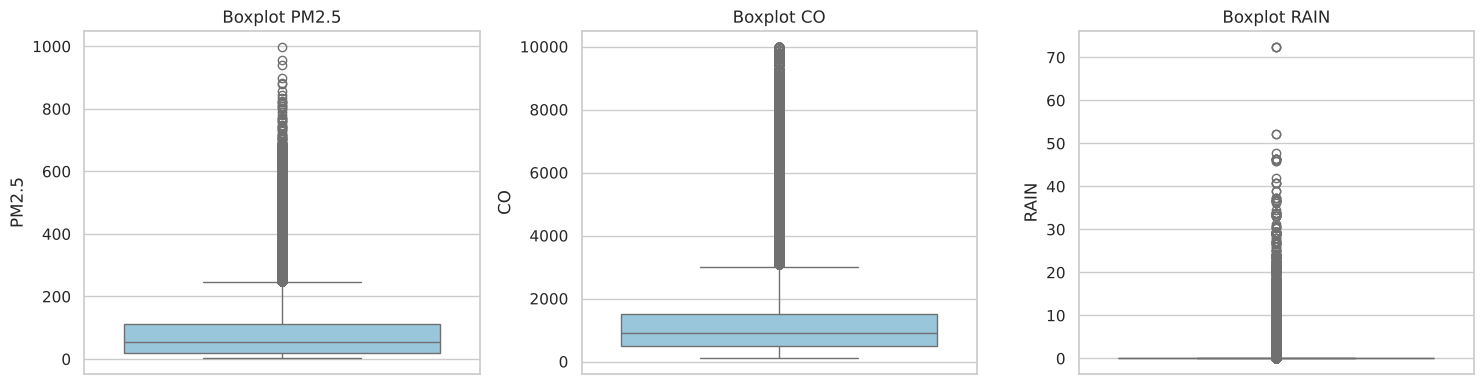

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["PM2.5", "CO", "RAIN"]):
    sns.boxplot(y=air_df[c], ax=a, color="#8ecae6")
    a.set_title(f"Boxplot {c}")
plt.tight_layout()
plt.show()

**Steps to Take:**
- Outlier menurut IQR cukup banyak pada polutan dan hujan, tetapi sifatnya **right-skewed alami** (kabut asap berat, hujan lebat), bukan kesalahan input. Outlier **tidak dihapus**, karena justru episode polusi ekstrem yang ingin dianalisis. Untuk mengurangi pengaruh nilai ekstrem, analisis korelasi memakai **Spearman** dan perbandingan memakai rata-rata sekaligus median.

**Insight:**
- Masalah kualitas data yang ditemukan: **missing value**, **invalid value (nilai cap 999)**, **inconsistent value (PM2.5 > PM10)**, dan **outlier** (dipertahankan dengan alasan domain). Tidak ada data duplikat.

### Cleaning Data

#### Membuat kolom datetime dan mengurutkan data

In [10]:
air_df["datetime"] = pd.to_datetime(air_df[["year", "month", "day", "hour"]])
air_df = air_df.drop(columns=["No"]).sort_values(["station", "datetime"]).reset_index(drop=True)
air_df[["station", "datetime"]].head()

,station,datetime
0,Aotizhongxin,2013-03-01 00:00:00
1,Aotizhongxin,2013-03-01 01:00:00
2,Aotizhongxin,2013-03-01 02:00:00
3,Aotizhongxin,2013-03-01 03:00:00
4,Aotizhongxin,2013-03-01 04:00:00


#### Fixing invalid value: nilai batas sensor 999

In [11]:
air_df[["PM2.5", "PM10"]] = air_df[["PM2.5", "PM10"]].replace(999, np.nan)
print(air_df[["PM2.5", "PM10"]].max())

PM2.5    957.0
PM10     995.0
dtype: float64


#### Fixing missing value: interpolasi per stasiun

In [12]:
num_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
before = air_df[num_cols + ["wd"]].isna().sum()

air_df[num_cols] = air_df.groupby("station")[num_cols].transform(
    lambda s: s.interpolate(method="linear", limit=24, limit_direction="both")
)
air_df["wd"] = air_df.groupby("station")["wd"].transform(lambda s: s.ffill(limit=24).bfill(limit=24))

after = air_df[num_cols + ["wd"]].isna().sum()
pd.DataFrame({"sebelum": before, "sesudah": after})

,sebelum,sesudah
PM2.5,8740,946
PM10,6452,651
SO2,9021,1285
NO2,12116,2599
CO,20701,7560
O3,13277,2068
TEMP,398,0
PRES,393,0
DEWP,403,0
RAIN,390,0


#### Fixing inconsistent value: PM10 minimal sama dengan PM2.5

In [13]:
mask = air_df["PM2.5"] > air_df["PM10"]
print("Baris dikoreksi:", mask.sum())
air_df.loc[mask, "PM10"] = air_df.loc[mask, "PM2.5"]
print("Sisa baris PM2.5 > PM10:", (air_df["PM2.5"] > air_df["PM10"]).sum())

Baris dikoreksi: 22625
Sisa baris PM2.5 > PM10: 0


#### Membuat kolom turunan (periode, musim, kategori PM2.5)

In [14]:
def get_season(m):
    if m in (12, 1, 2):  return "Dingin (Des-Feb)"
    if m in (3, 4, 5):   return "Semi (Mar-Mei)"
    if m in (6, 7, 8):   return "Panas (Jun-Agu)"
    return "Gugur (Sep-Nov)"

air_df["date"] = air_df["datetime"].dt.normalize()
air_df["periode_start"] = np.where(air_df["month"] >= 3, air_df["year"], air_df["year"] - 1)
air_df["periode"] = air_df["periode_start"].astype(str) + "/" + (air_df["periode_start"] + 1).astype(str).str[-2:]
air_df["musim"] = air_df["month"].apply(get_season)

# Kategori PM2.5 mengacu pada breakpoint AQI China (HJ 633-2012) untuk rata-rata 24 jam, µg/m³
bins = [0, 35, 75, 115, 150, 250, np.inf]
labels = ["Baik", "Sedang", "Tidak sehat (sensitif)", "Tidak sehat", "Sangat tidak sehat", "Berbahaya"]
air_df["kategori_pm25"] = pd.cut(air_df["PM2.5"], bins=bins, labels=labels, include_lowest=True)

print(air_df["periode"].value_counts().sort_index())
air_df.head()

periode
2013/14    105120
2014/15    105120
2015/16    105408
2016/17    105120
Name: count, dtype: int64


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime,date,periode_start,periode,musim,kategori_pm25
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00,2013-03-01,2013,2013/14,Semi (Mar-Mei),Baik
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00,2013-03-01,2013,2013/14,Semi (Mar-Mei),Baik
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00,2013-03-01,2013,2013/14,Semi (Mar-Mei),Baik
3,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00,2013-03-01,2013,2013/14,Semi (Mar-Mei),Baik
4,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00,2013-03-01,2013,2013/14,Semi (Mar-Mei),Baik


**Insight:**
- Data bersih: tidak ada nilai cap 999, tidak ada PM2.5 > PM10, dan missing value berkurang drastis (sisa merupakan celah panjang > 24 jam yang sengaja tidak diisi).
- Kolom `periode` (Maret–Februari) membuat 4 periode tahunan **penuh** (2013/14 – 2016/17), sehingga perbandingan antar tahun adil. Tahun kalender 2013 dan 2017 hanya parsial.
- Kategori PM2.5 memakai breakpoint AQI China; karena diterapkan pada data per jam, ini adalah pendekatan (aproksimasi) untuk menggambarkan sebaran tingkat polusi.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik data bersih

In [15]:
air_df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
PM2.5,419822.0,79.90,81.00,2.00,20.0,55.0,111.0,957.0
PM10,420117.0,106.26,92.81,2.00,37.0,84.0,147.0,995.0
SO2,419483.0,15.89,21.89,0.29,3.0,7.0,20.0,500.0
NO2,418169.0,50.50,35.18,1.03,23.0,43.0,71.0,290.0
CO,413208.0,1233.91,1169.94,100.00,500.0,900.0,1500.0,10000.0
O3,418700.0,57.14,56.81,0.21,10.0,44.0,82.0,1071.0
TEMP,420768.0,13.53,11.44,-19.90,3.1,14.5,23.3,41.6
PRES,420768.0,1010.75,10.47,982.40,1002.3,1010.4,1019.0,1042.8
DEWP,420768.0,2.48,13.80,-43.40,-8.9,3.0,15.1,29.1
RAIN,420768.0,0.06,0.82,0.00,0.0,0.0,0.0,72.5


### Explore Pertanyaan 1: pola bulan, jam, dan musim

In [16]:
# Rata-rata PM2.5 per bulan (seluruh stasiun, seluruh tahun)
monthly = air_df.groupby("month")["PM2.5"].mean().round(1)
print("Rata-rata PM2.5 per bulan:"); print(monthly.to_string())

# Rata-rata PM2.5 per jam
hourly = air_df.groupby("hour")["PM2.5"].mean().round(1)
print("\nJam tertinggi:", hourly.idxmax(), "->", hourly.max(), "| jam terendah:", hourly.idxmin(), "->", hourly.min())

# Rata-rata harian per stasiun (24 jam), lalu persentase hari > 75 µg/m3 per musim
daily = air_df.groupby(["station", "date"]).agg(pm25=("PM2.5", "mean"), musim=("musim", "first"), month=("month", "first"), periode=("periode", "first")).reset_index()
daily["lewat_baku_mutu"] = daily["pm25"] > 75
season_stat = daily.groupby("musim").agg(rata2_pm25=("pm25", "mean"), pct_hari_lewat=("lewat_baku_mutu", "mean")).round(3)
season_stat["pct_hari_lewat"] = (season_stat["pct_hari_lewat"] * 100).round(1)
print("\nStatistik per musim:"); season_stat.sort_values("pct_hari_lewat", ascending=False)

Rata-rata PM2.5 per bulan:
month
1      93.8
2      89.2
3      94.6
4      73.3
5      63.4
6      68.9
7      71.7
8      53.5
9      61.3
10     91.8
11     93.3
12    104.2

Jam tertinggi: 22 -> 89.1 | jam terendah: 7 -> 73.5



Statistik per musim:


,rata2_pm25,pct_hari_lewat
musim,,
Dingin (Des-Feb),95.882,45.2
Semi (Mar-Mei),77.191,41.1
Gugur (Sep-Nov),82.250,40.9
Panas (Jun-Agu),64.590,34.2


### Explore Pertanyaan 2: perbandingan stasiun dan tren periode

In [17]:
station_stat = daily.groupby("station").agg(
    rata2_pm25=("pm25", "mean"), median_pm25=("pm25", "median"), pct_hari_lewat=("lewat_baku_mutu", "mean")
)
station_stat["pct_hari_lewat"] = station_stat["pct_hari_lewat"] * 100
station_stat = station_stat.round(1).sort_values("rata2_pm25", ascending=False)
print(station_stat.to_string())

period_stat = air_df.groupby("periode")["PM2.5"].mean().round(1).to_frame("rata2_pm25")
period_stat["perubahan_vs_periode_sebelumnya_%"] = period_stat["rata2_pm25"].pct_change().mul(100).round(1)
print("\nTren per periode:"); period_stat

               rata2_pm25  median_pm25  pct_hari_lewat
station                                               
Dongsi               86.1         66.1            43.5
Nongzhanguan         85.1         63.3            42.8
Wanshouxigong        85.1         64.6            42.8
Gucheng              84.1         65.5            43.1
Wanliu               83.5         64.6            42.8
Guanyuan             82.9         63.8            42.2
Aotizhongxin         82.9         63.1            42.0
Tiantan              82.0         62.7            41.3
Shunyi               79.6         60.3            40.8
Changping            71.1         53.1            35.9
Huairou              69.4         50.6            34.4
Dingling             66.8         47.0            32.2

Tren per periode:


,rata2_pm25,perubahan_vs_periode_sebelumnya_%
periode,,
2013/14,87.1,NaN
2014/15,81.5,-6.4
2015/16,72.9,-10.6
2016/17,78.1,7.1


In [18]:
pivot_period = daily.pivot_table(index="station", columns="periode", values="pm25", aggfunc="mean").round(1)
pivot_period["perubahan_13/14_ke_16/17_%"] = ((pivot_period["2016/17"] / pivot_period["2013/14"] - 1) * 100).round(1)
pivot_period.sort_values("perubahan_13/14_ke_16/17_%")

periode,2013/14,2014/15,2015/16,2016/17,perubahan_13/14_ke_16/17_%
station,,,,,
Wanliu,98.5,84.1,73.6,77.7,-21.1
Changping,79.2,76.3,61.8,67.0,-15.4
Huairou,76.2,71.2,65.4,65.0,-14.7
Dingling,73.0,70.7,58.1,65.5,-10.3
Tiantan,89.3,83.1,75.5,80.2,-10.2
Aotizhongxin,88.7,85.8,76.7,80.4,-9.4
Nongzhanguan,91.8,87.9,77.4,83.2,-9.4
Shunyi,84.7,80.3,75.7,77.9,-8.0
Wanshouxigong,92.3,85.1,77.6,85.3,-7.6


### Explore Pertanyaan 3: pengaruh meteorologi

In [19]:
met_cols = ["WSPM", "TEMP", "PRES", "DEWP", "RAIN"]
corr = air_df[["PM2.5"] + met_cols].corr(method="spearman")["PM2.5"].drop("PM2.5").round(3)
print("Korelasi Spearman dengan PM2.5:"); print(corr.sort_values().to_string())

wd_stat = air_df.groupby("wd")["PM2.5"].agg(["mean", "median", "count"]).round(1).sort_values("mean", ascending=False)
print("\nPM2.5 per arah angin:"); print(wd_stat.to_string())

air_df["kelas_angin"] = pd.cut(air_df["WSPM"], bins=[-0.01, 0.5, 1, 2, 3, 20],
                               labels=["Tenang (<=0.5)", "Lemah (0.5-1)", "Sedang (1-2)", "Cukup kuat (2-3)", "Kuat (>3)"])
wind_stat = air_df.groupby("kelas_angin", observed=True)["PM2.5"].agg(["mean", "count"]).round(1)
print("\nPM2.5 per kelas kecepatan angin (m/s):"); wind_stat

Korelasi Spearman dengan PM2.5:
WSPM   -0.328
PRES   -0.069
TEMP   -0.024
RAIN   -0.021
DEWP    0.239

PM2.5 per arah angin:
      mean  median  count
wd                       
ESE  102.0    80.0  24220
E    101.7    77.0  29773
ENE   97.8    71.0  34148
SE    96.8    78.0  20165
SSE   93.6    76.0  17687
S     89.4    71.0  19402
NE    86.3    57.0  43564
SSW   84.2    68.0  22565
SW    79.6    62.0  28947
WSW   77.3    57.0  20037
W     74.0    49.0  17624
NNE   71.3    40.0  28268
N     67.4    35.0  30915
WNW   56.8    25.0  24410
NNW   53.9    23.0  25315
NW    51.9    20.5  32782

PM2.5 per kelas kecepatan angin (m/s):


,mean,count
kelas_angin,,
Tenang (<=0.5),104.0,41183
Lemah (0.5-1),101.2,93899
Sedang (1-2),84.7,164438
Cukup kuat (2-3),59.4,65672
Kuat (>3),35.4,54630


**Insight:**
- Ringkasan temuan EDA dibahas lengkap pada bagian visualisasi dan kesimpulan di bawah, setelah pola terlihat jelas pada grafik.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada bulan dan jam berapa PM2.5 paling tinggi, dan berapa % hari per musim yang melampaui 75 µg/m³?

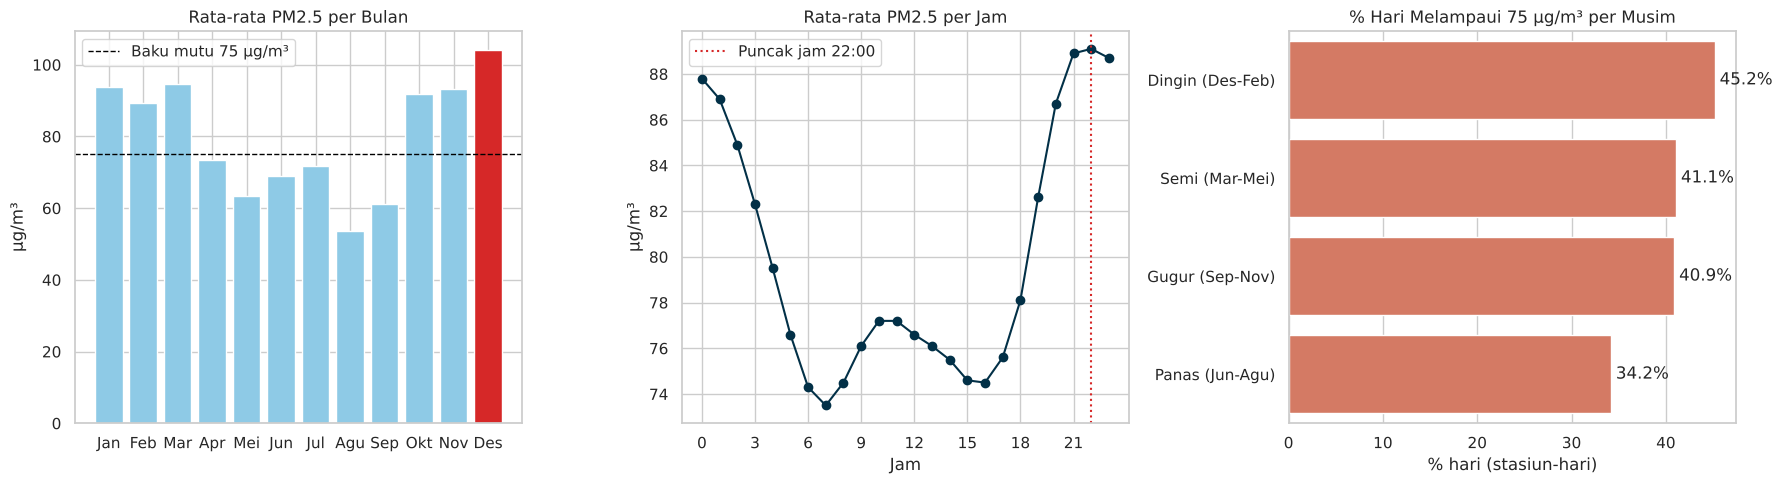

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) rata-rata per bulan
month_names = ["Jan","Feb","Mar","Apr","Mei","Jun","Jul","Agu","Sep","Okt","Nov","Des"]
colors = ["#d62828" if v == monthly.max() else "#8ecae6" for v in monthly.values]
axes[0].bar(month_names, monthly.values, color=colors)
axes[0].axhline(75, color="black", ls="--", lw=1, label="Baku mutu 75 µg/m³")
axes[0].set_title("Rata-rata PM2.5 per Bulan"); axes[0].set_ylabel("µg/m³"); axes[0].legend()

# (b) pola per jam
axes[1].plot(hourly.index, hourly.values, marker="o", color="#023047")
axes[1].axvline(hourly.idxmax(), color="#d62828", ls=":", label=f"Puncak jam {hourly.idxmax()}:00")
axes[1].set_title("Rata-rata PM2.5 per Jam"); axes[1].set_xlabel("Jam"); axes[1].set_ylabel("µg/m³")
axes[1].set_xticks(range(0, 24, 3)); axes[1].legend()

# (c) % hari melampaui baku mutu per musim
order = season_stat.sort_values("pct_hari_lewat", ascending=False)
sns.barplot(x=order["pct_hari_lewat"], y=order.index, ax=axes[2], color="#e76f51")
for i, v in enumerate(order["pct_hari_lewat"]):
    axes[2].text(v + 0.5, i, f"{v:.1f}%", va="center")
axes[2].set_title("% Hari Melampaui 75 µg/m³ per Musim"); axes[2].set_xlabel("% hari (stasiun-hari)"); axes[2].set_ylabel("")
plt.tight_layout(); plt.show()

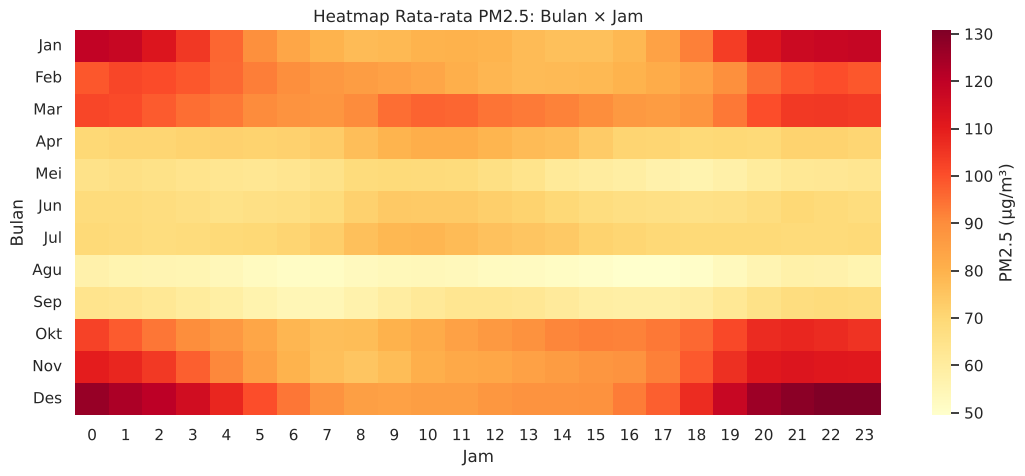

In [21]:
heat = air_df.pivot_table(index="month", columns="hour", values="PM2.5", aggfunc="mean")
plt.figure(figsize=(13, 5))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "PM2.5 (µg/m³)"}, yticklabels=month_names)
plt.title("Heatmap Rata-rata PM2.5: Bulan × Jam"); plt.xlabel("Jam"); plt.ylabel("Bulan"); plt.yticks(rotation=0)
plt.show()

**Insight Pertanyaan 1:**
- **Bulan tertinggi: Desember (104,2 µg/m³)**, disusul Maret (94,6), Januari (93,8), dan November (93,3). Bulan terendah adalah Agustus (53,5). Rata-rata bulanan Okt–Mar hampir selalu di atas baku mutu 75 µg/m³, sedangkan Mei–Sep berada di bawahnya.
- **Pola jam relatif landai**: puncak pukul **22:00 (89,1 µg/m³)** dan terendah pukul **07:00 (73,5 µg/m³)**, selisih ±15 µg/m³ saja. Heatmap menunjukkan variasi antar bulan jauh lebih besar daripada variasi antar jam.
- **Musim dingin paling buruk**: rata-rata 95,9 µg/m³ dan **45,2%** hari melampaui 75 µg/m³, dibanding musim panas 64,6 µg/m³ dan 34,2%. Musim semi (41,1%) dan gugur (40,9%) berada di antara keduanya. Artinya, bahkan pada musim terbersih, lebih dari sepertiga hari tetap melampaui baku mutu.

### Pertanyaan 2: Stasiun mana yang tertinggi dan bagaimana tren antar periode?

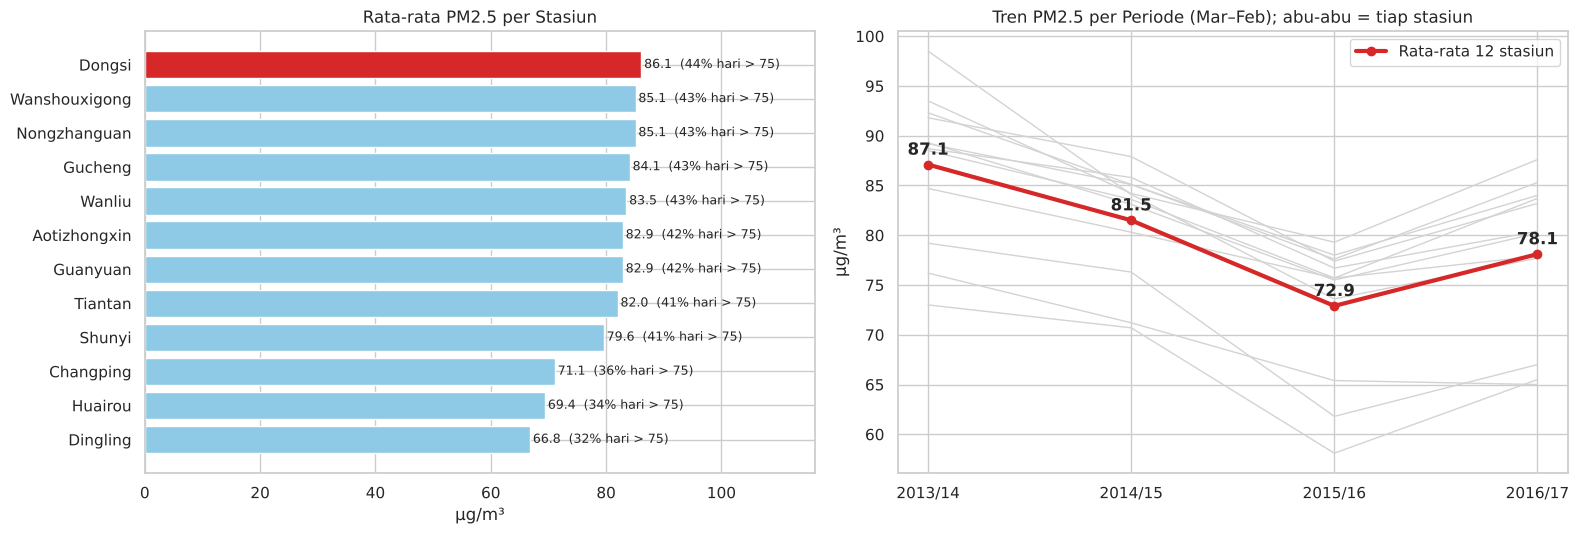

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# (a) peringkat stasiun
st = station_stat.sort_values("rata2_pm25")
cols = ["#d62828" if s == station_stat["rata2_pm25"].idxmax() else "#8ecae6" for s in st.index]
axes[0].barh(st.index, st["rata2_pm25"], color=cols)
for i, (v, p) in enumerate(zip(st["rata2_pm25"], st["pct_hari_lewat"])):
    axes[0].text(v + 0.5, i, f"{v:.1f}  ({p:.0f}% hari > 75)", va="center", fontsize=9)
axes[0].set_xlim(0, st["rata2_pm25"].max() * 1.35)
axes[0].set_title("Rata-rata PM2.5 per Stasiun"); axes[0].set_xlabel("µg/m³")

# (b) tren per periode: rata-rata seluruh stasiun + garis tiap stasiun
for s in pivot_period.index:
    axes[1].plot(period_stat.index, pivot_period.loc[s, period_stat.index], color="lightgray", lw=1)
axes[1].plot(period_stat.index, period_stat["rata2_pm25"], marker="o", color="#d62828", lw=3, label="Rata-rata 12 stasiun")
for x, y in zip(period_stat.index, period_stat["rata2_pm25"]):
    axes[1].text(x, y + 1, f"{y:.1f}", ha="center", fontweight="bold")
axes[1].set_title("Tren PM2.5 per Periode (Mar–Feb); abu-abu = tiap stasiun")
axes[1].set_ylabel("µg/m³"); axes[1].legend()
plt.tight_layout(); plt.show()

**Insight Pertanyaan 2:**
- **Dongsi** adalah stasiun dengan polusi tertinggi (rata-rata **86,1 µg/m³**, 43,5% hari > 75 µg/m³), diikuti Nongzhanguan dan Wanshouxigong (85,1). **Dingling** terendah (66,8 µg/m³, 32,2% hari), sehingga Dongsi sekitar **29% lebih tinggi**.
- Pola spasial jelas: stasiun di pusat kota (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng, Wanliu) lebih berpolusi, sedangkan stasiun pinggiran utara (Dingling, Huairou, Changping) lebih bersih (lihat peta).
- **Tren periode**: rata-rata 12 stasiun turun dari **87,1** (2013/14) menjadi 81,5 (2014/15) dan **72,9** (2015/16), tetapi **naik kembali ke 78,1** pada 2016/17 (+7,1%). Secara total 2013/14 → 2016/17 turun **10,3%**. Penurunan terbesar terjadi di Wanliu (−21,1%), sedangkan Guanyuan (−5,4%), Gucheng (−5,8%), dan Dongsi (−6,3%) membaik paling kecil.

### Pertanyaan 3: Seberapa kuat pengaruh cuaca dan arah angin mana yang paling berpolusi?

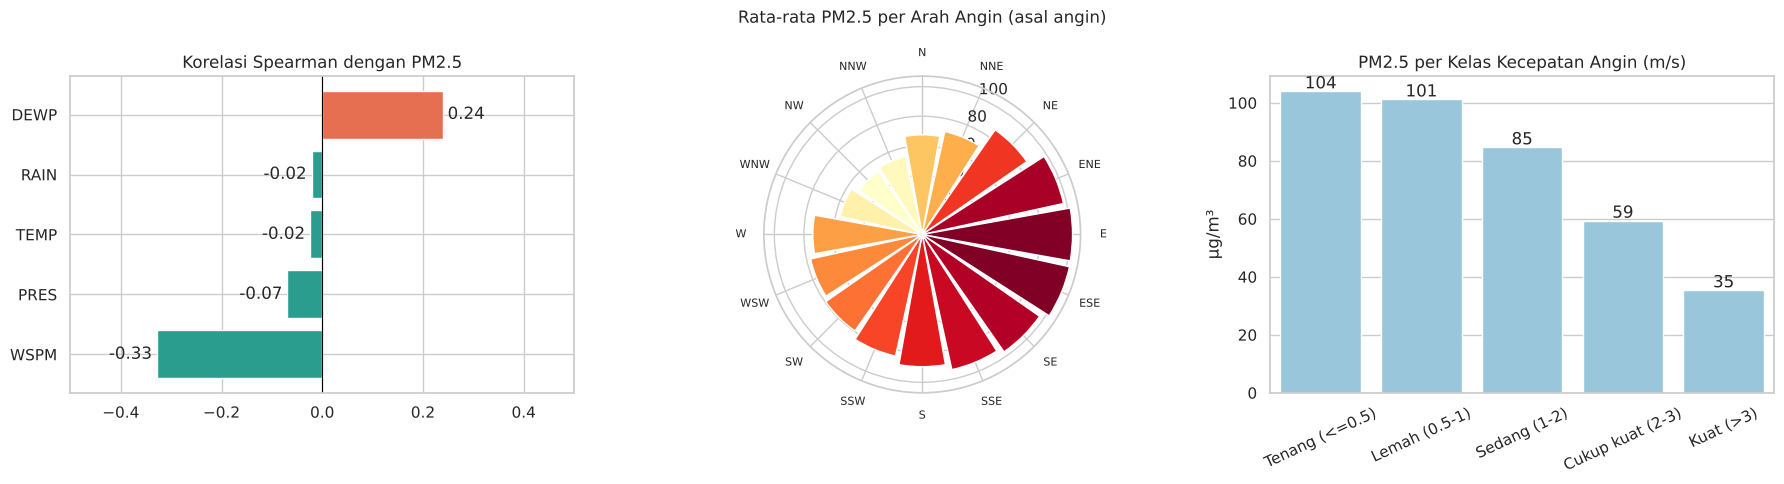

In [23]:
fig = plt.figure(figsize=(18, 5))

# (a) korelasi Spearman
ax1 = fig.add_subplot(1, 3, 1)
cs = corr.sort_values()
ax1.barh(cs.index, cs.values, color=["#2a9d8f" if v < 0 else "#e76f51" for v in cs.values])
for i, v in enumerate(cs.values):
    ax1.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right")
ax1.set_xlim(-0.5, 0.5); ax1.axvline(0, color="black", lw=0.8)
ax1.set_title("Korelasi Spearman dengan PM2.5")

# (b) wind rose rata-rata PM2.5 per arah angin
dirs = ["N","NNE","NE","ENE","E","ESE","SE","SSE","S","SSW","SW","WSW","W","WNW","NW","NNW"]
vals = air_df.groupby("wd")["PM2.5"].mean().reindex(dirs)
theta = np.linspace(0, 2*np.pi, 16, endpoint=False)
ax2 = fig.add_subplot(1, 3, 2, projection="polar")
ax2.set_theta_zero_location("N"); ax2.set_theta_direction(-1)
ax2.bar(theta, vals.values, width=2*np.pi/16*0.9, color=plt.cm.YlOrRd((vals.values - vals.min()) / (vals.max() - vals.min())))
ax2.set_xticks(theta); ax2.set_xticklabels(dirs, fontsize=8)
ax2.set_title("Rata-rata PM2.5 per Arah Angin (asal angin)", pad=18)

# (c) kelas kecepatan angin
ax3 = fig.add_subplot(1, 3, 3)
sns.barplot(x=wind_stat.index.astype(str), y=wind_stat["mean"], ax=ax3, color="#8ecae6")
for i, v in enumerate(wind_stat["mean"]):
    ax3.text(i, v + 1, f"{v:.0f}", ha="center")
ax3.set_title("PM2.5 per Kelas Kecepatan Angin (m/s)"); ax3.set_ylabel("µg/m³"); ax3.set_xlabel("")
ax3.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

**Insight Pertanyaan 3:**
- **Kecepatan angin adalah faktor cuaca paling berpengaruh**: korelasi Spearman −0,33 (angin kencang menyapu polutan). Titik embun berkorelasi positif lemah (+0,24), mengindikasikan polusi lebih tinggi saat udara lembap. Tekanan (−0,07), suhu (−0,02), dan hujan (−0,02) hampir tidak berkorelasi secara monoton.
- **Kelas kecepatan angin**: saat angin tenang/lemah (≤1 m/s) rata-rata PM2.5 mencapai **101–104 µg/m³**, sedangkan saat angin kuat (>3 m/s) hanya **35,4 µg/m³** (sekitar 66% lebih rendah).
- **Arah angin**: angin dari **ESE (102,0)** dan **E (101,7)**, lalu ENE dan SE (±97–98) membawa PM2.5 tertinggi. Angin dari **NW (51,9)**, NNW (53,9), dan WNW (56,8) membawa udara paling bersih, kira-kira separuh dari angin timur.

## Analisis Lanjutan (Opsional)

Teknik yang digunakan (tanpa algoritma *machine learning*):
1. **Manual grouping / binning**: pengelompokan PM2.5 ke kategori kualitas udara (breakpoint AQI China) dan kecepatan angin ke 5 kelas.
2. **Geospatial analysis**: peta sebaran rata-rata PM2.5 antar stasiun. *Dataset tidak menyertakan koordinat; koordinat di bawah adalah **perkiraan lokasi stasiun** yang ditambahkan manual (akurasi ±beberapa ratus meter) dan cukup untuk melihat pola spasial.*

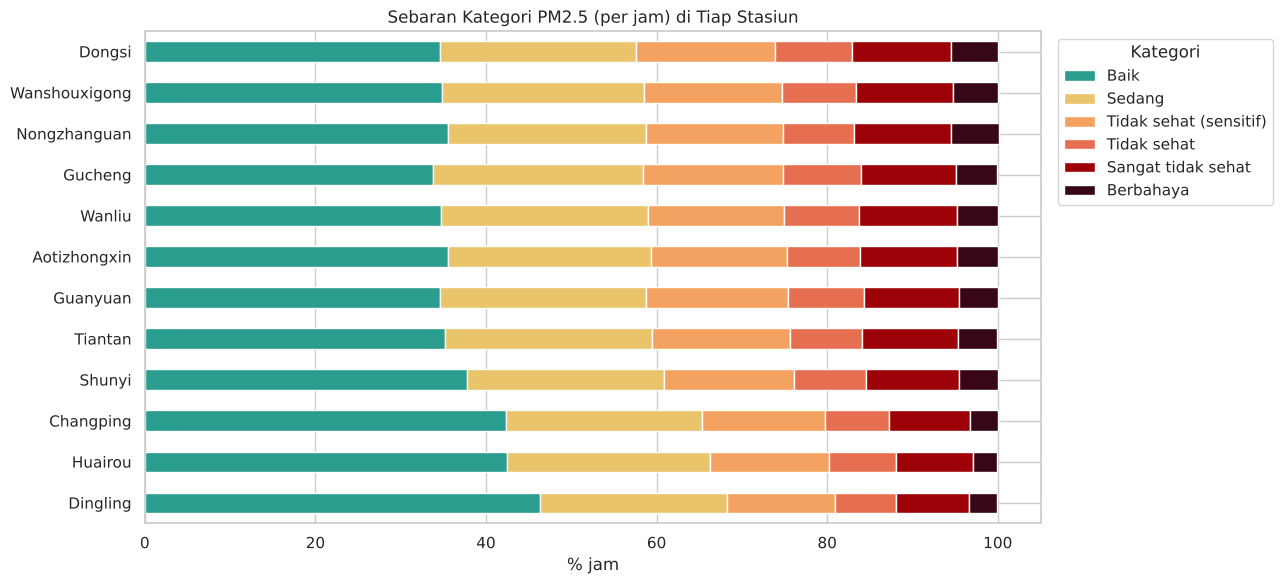

kategori_pm25,Baik,Sedang,Tidak sehat (sensitif),Tidak sehat,Sangat tidak sehat,Berbahaya
station,,,,,,
Dingling,46.3,21.9,12.7,7.2,8.5,3.3
Huairou,42.5,23.8,13.9,7.9,9.0,2.8
Changping,42.3,23.0,14.4,7.6,9.5,3.2
Shunyi,37.8,23.1,15.2,8.5,10.9,4.5
Tiantan,35.2,24.3,16.2,8.4,11.2,4.6
Guanyuan,34.6,24.2,16.6,8.9,11.1,4.6
Aotizhongxin,35.5,23.8,16.0,8.6,11.3,4.8
Wanliu,34.7,24.3,15.9,8.8,11.5,4.8
Gucheng,33.8,24.6,16.4,9.2,11.1,4.8


In [24]:
cat_station = (air_df.dropna(subset=["PM2.5"]).groupby("station")["kategori_pm25"]
               .value_counts(normalize=True).unstack().mul(100).round(1))
cat_station = cat_station.loc[station_stat.sort_values("rata2_pm25").index]

ax = cat_station.plot(kind="barh", stacked=True, figsize=(13, 6),
                      color=["#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "#9d0208", "#370617"])
ax.set_title("Sebaran Kategori PM2.5 (per jam) di Tiap Stasiun"); ax.set_xlabel("% jam"); ax.set_ylabel("")
ax.legend(title="Kategori", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
cat_station.round(1)

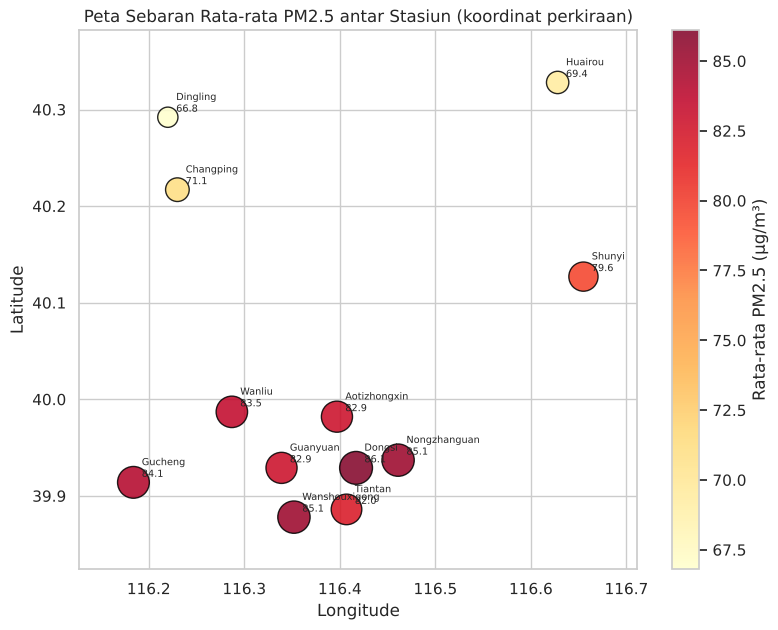

In [25]:
coords = {  # koordinat perkiraan (lat, lon)
    "Aotizhongxin": (39.982, 116.397), "Changping": (40.217, 116.230), "Dingling": (40.292, 116.220),
    "Dongsi": (39.929, 116.417), "Guanyuan": (39.929, 116.339), "Gucheng": (39.914, 116.184),
    "Huairou": (40.328, 116.628), "Nongzhanguan": (39.937, 116.461), "Shunyi": (40.127, 116.655),
    "Tiantan": (39.886, 116.407), "Wanliu": (39.987, 116.287), "Wanshouxigong": (39.878, 116.352),
}
geo = station_stat.join(pd.DataFrame(coords, index=["lat", "lon"]).T)

plt.figure(figsize=(9, 7))
sc = plt.scatter(geo["lon"], geo["lat"], s=(geo["rata2_pm25"] - 55) * 18, c=geo["rata2_pm25"],
                 cmap="YlOrRd", edgecolor="black", alpha=0.85)
for s, r in geo.iterrows():
    plt.annotate(f"{s}\n{r['rata2_pm25']:.1f}", (r["lon"], r["lat"]), textcoords="offset points", xytext=(6, 4), fontsize=7)
plt.colorbar(sc, label="Rata-rata PM2.5 (µg/m³)")
plt.title("Peta Sebaran Rata-rata PM2.5 antar Stasiun (koordinat perkiraan)")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.margins(0.12)
plt.show()

**Insight:**
- Persentase jam berkategori **Sangat tidak sehat + Berbahaya** (>150 µg/m³) berkisar 11,8% (Dingling) hingga 17,1% (Dongsi); stasiun pusat kota memiliki porsi jam kategori "Baik" paling kecil (±34–35%), sedangkan Dingling mencapai 46,3%.
- Peta menegaskan gradien spasial: lingkaran terbesar/terpanas berada di pusat kota, sedangkan wilayah utara (Dingling, Huairou, Changping) lebih rendah. Hal ini konsisten dengan sumber emisi perkotaan (lalu lintas, pemukiman) yang lebih padat di pusat.

### Menyimpan data bersih untuk dashboard

In [26]:
import os
os.makedirs("dashboard", exist_ok=True)
keep = ["station", "datetime", "PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"]
air_df[keep].to_csv("dashboard/main_data.csv", index=False)
print("Tersimpan:", os.path.getsize("dashboard/main_data.csv") / 1e6, "MB")

Tersimpan: 37.702726 MB


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** PM2.5 paling tinggi pada **Desember (104,2 µg/m³)** dan musim dingin (95,9 µg/m³; **45,2% hari melampaui 75 µg/m³**), dengan puncak harian sekitar pukul 22:00 (89,1 µg/m³). Variasi musiman jauh lebih besar daripada variasi harian, dan bahkan pada musim panas 34,2% hari tetap melampaui baku mutu.
- **Conclusion pertanyaan 2:** **Dongsi** adalah stasiun paling berpolusi (86,1 µg/m³; 43,5% hari > 75), sementara **Dingling** terendah (66,8 µg/m³; 32,2%). Rata-rata PM2.5 turun **10,3%** dari periode 2013/14 (87,1) ke 2016/17 (78,1), namun sempat naik 7,1% pada 2016/17 setelah titik terendah 72,9 di 2015/16, sehingga perbaikan belum konsisten, terutama di stasiun pusat kota.
- **Conclusion pertanyaan 3:** **Kecepatan angin** adalah faktor cuaca terkuat (Spearman −0,33): angin ≤1 m/s menghasilkan PM2.5 101–104 µg/m³ vs 35,4 µg/m³ saat >3 m/s. Angin dari **timur–tenggara (ESE/E ≈ 102 µg/m³)** membawa polusi tertinggi, sedangkan angin **barat laut (NW ≈ 52 µg/m³)** paling bersih. Suhu, tekanan, dan hujan berkorelasi sangat lemah dengan PM2.5.

**Rekomendasi Action Item:**
1. **Pengendalian berbasis musim:** fokuskan pembatasan emisi (pemanas, industri, lalu lintas berat) pada **Oktober–Maret**, terutama Desember, karena rata-rata bulanan di atas baku mutu dan 45% hari musim dingin melampaui 75 µg/m³.
2. **Prioritas wilayah:** alokasikan intervensi dan penambahan sensor pada kawasan pusat kota (**Dongsi, Nongzhanguan, Wanshouxigong, Gucheng**) yang rata-rata dan frekuensi pelampauannya tertinggi.
3. **Sistem peringatan dini berbasis cuaca:** keluarkan peringatan ketika prakiraan menunjukkan **angin ≤1 m/s** dan/atau **angin dari sektor E–SE**, kondisi yang rata-rata menghasilkan PM2.5 ≈100 µg/m³ atau lebih; imbau masyarakat sensitif mengurangi aktivitas luar ruang pada kondisi itu.
4. **Evaluasi kebijakan:** selidiki penyebab kenaikan 2016/17 (+7,1%) dan pelajari praktik di Wanliu (penurunan terbesar, −21,1%) untuk direplikasi di Guanyuan, Gucheng, dan Dongsi yang membaik paling lambat.
5. **Kesehatan publik:** karena jam harian relatif merata (puncak ±22:00), edukasi sebaiknya tidak hanya pada jam sibuk, melainkan berbasis tingkat polusi harian.

**Keterbatasan analisis:** korelasi bukan kausalitas; kategori AQI per jam adalah aproksimasi; koordinat stasiun adalah perkiraan; data berakhir Februari 2017 sehingga tidak mencerminkan kondisi terkini.